In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

In [3]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 5000

df = pd.DataFrame({
    "customerID": [f"CUST{i:05d}" for i in range(1, n + 1)],
    "gender": np.random.choice(["Male", "Female"], n),
    "SeniorCitizen": np.random.choice([0, 1], n, p=[0.84, 0.16]),
    "Partner": np.random.choice(["Yes", "No"], n),
    "Dependents": np.random.choice(["Yes", "No"], n, p=[0.30, 0.70]),
    "tenure": np.random.randint(1, 73, n),
    "PhoneService": np.random.choice(["Yes", "No"], n, p=[0.90, 0.10]),
    "InternetService": np.random.choice(
        ["DSL", "Fiber optic", "No"],
        n,
        p=[0.35, 0.45, 0.20]
    ),
    "Contract": np.random.choice(
        ["Month-to-month", "One year", "Two year"],
        n,
        p=[0.55, 0.25, 0.20]
    ),
    "PaymentMethod": np.random.choice(
        [
            "Electronic check",
            "Mailed check",
            "Bank transfer",
            "Credit card"
        ],
        n
    ),
    "MonthlyCharges": np.round(
        np.random.uniform(20, 120, n), 2
    )
})

# Create TotalCharges
df["TotalCharges"] = np.round(
    df["MonthlyCharges"] * df["tenure"] +
    np.random.normal(0, 100, n),
    2
)

df["TotalCharges"] = df["TotalCharges"].clip(lower=0)

# Create realistic churn probability
churn_score = (
    0.15
    + (df["Contract"] == "Month-to-month") * 0.25
    + (df["InternetService"] == "Fiber optic") * 0.10
    + (df["MonthlyCharges"] > 80) * 0.10
    + (df["tenure"] < 12) * 0.15
    + (df["PaymentMethod"] == "Electronic check") * 0.08
    - (df["Contract"] == "Two year") * 0.15
    - (df["tenure"] > 48) * 0.10
)

churn_probability = np.clip(churn_score, 0.02, 0.85)

df["Churn"] = np.where(
    np.random.random(n) < churn_probability,
    "Yes",
    "No"
)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,CUST00001,Male,0,No,No,28,Yes,No,Month-to-month,Bank transfer,49.88,1387.38,No
1,CUST00002,Female,0,No,No,22,Yes,DSL,Month-to-month,Bank transfer,91.73,1935.22,No
2,CUST00003,Male,0,No,Yes,16,Yes,Fiber optic,One year,Mailed check,50.11,588.65,No
3,CUST00004,Male,1,Yes,No,13,Yes,Fiber optic,One year,Bank transfer,34.72,462.06,No
4,CUST00005,Male,0,Yes,No,62,Yes,Fiber optic,Month-to-month,Credit card,20.75,1411.01,Yes


In [4]:
df.to_csv("../data/customer_churn.csv", index=False)

print("Dataset created successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset created successfully!
Rows: 5000
Columns: 13


In [5]:
df = pd.read_csv("../data/customer_churn.csv")

print(df.head())
print(df.shape)

  customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  CUST00001    Male              0      No         No      28          Yes   
1  CUST00002  Female              0      No         No      22          Yes   
2  CUST00003    Male              0      No        Yes      16          Yes   
3  CUST00004    Male              1     Yes         No      13          Yes   
4  CUST00005    Male              0     Yes         No      62          Yes   

  InternetService        Contract  PaymentMethod  MonthlyCharges  \
0              No  Month-to-month  Bank transfer           49.88   
1             DSL  Month-to-month  Bank transfer           91.73   
2     Fiber optic        One year   Mailed check           50.11   
3     Fiber optic        One year  Bank transfer           34.72   
4     Fiber optic  Month-to-month    Credit card           20.75   

   TotalCharges Churn  
0       1387.38    No  
1       1935.22    No  
2        588.65    No  
3        462.06    N

In [6]:
df["Churn"].value_counts()

Churn
No     3218
Yes    1782
Name: count, dtype: int64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customerID       5000 non-null   str    
 1   gender           5000 non-null   str    
 2   SeniorCitizen    5000 non-null   int64  
 3   Partner          5000 non-null   str    
 4   Dependents       5000 non-null   str    
 5   tenure           5000 non-null   int64  
 6   PhoneService     5000 non-null   str    
 7   InternetService  5000 non-null   str    
 8   Contract         5000 non-null   str    
 9   PaymentMethod    5000 non-null   str    
 10  MonthlyCharges   5000 non-null   float64
 11  TotalCharges     5000 non-null   float64
 12  Churn            5000 non-null   str    
dtypes: float64(2), int64(2), str(9)
memory usage: 775.4 KB


In [8]:
print("Total missing values:", df.isnull().sum().sum())


Total missing values: 0


In [12]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
df = df.drop_duplicates()
print(df.shape)
for column in df.columns:
    print("\n", column)
    print(df[column].unique())


Duplicate rows: 0
Duplicate customer IDs: 0
(5000, 13)

 customerID
<ArrowStringArray>
['CUST00001', 'CUST00002', 'CUST00003', 'CUST00004', 'CUST00005', 'CUST00006',
 'CUST00007', 'CUST00008', 'CUST00009', 'CUST00010',
 ...
 'CUST04991', 'CUST04992', 'CUST04993', 'CUST04994', 'CUST04995', 'CUST04996',
 'CUST04997', 'CUST04998', 'CUST04999', 'CUST05000']
Length: 5000, dtype: str

 gender
<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

 SeniorCitizen
[0 1]

 Partner
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

 Dependents
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

 tenure
[28 22 16 13 62 43 32 67 57 65 69 49 33 19 36 70 15 24 27 23 41 56 29 31
 18  6 52 40 42 68 10  9 61 11  8  2 55 17  3 35 66  1  7 20 21 51 46 71
 64 58 45 53 44 14 34 37 25 48 26 12  5 38 60 54 72 47 30 50 39 63 59  4]

 PhoneService
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

 InternetService
<ArrowStringArray>
['No', 'DSL', 'Fiber optic']
Length: 3, dtype: str

 Contra

In [17]:
df.head()
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.154400,36.321200,70.041902,2535.320242
std,0.361368,20.774108,28.964659,1882.321889
min,0.000000,1.000000,20.020000,0.000000
25%,0.000000,18.000000,45.275000,1030.440000
50%,0.000000,36.000000,69.645000,2091.790000
75%,0.000000,54.000000,95.502500,3702.175000
max,1.000000,72.000000,119.940000,8565.120000


In [19]:
print(df["Churn"].value_counts())
print(
    df["Churn"].value_counts(normalize=True) * 100
)

Churn
No     3218
Yes    1782
Name: count, dtype: int64
Churn
No     64.36
Yes    35.64
Name: proportion, dtype: float64


In [20]:
df.to_csv(
    "../data/customer_churn_clean.csv",
    index=False
)

print("Clean dataset saved successfully!")

Clean dataset saved successfully!


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   gender           5000 non-null   str    
 1   SeniorCitizen    5000 non-null   int64  
 2   Partner          5000 non-null   str    
 3   Dependents       5000 non-null   str    
 4   tenure           5000 non-null   int64  
 5   PhoneService     5000 non-null   str    
 6   InternetService  5000 non-null   str    
 7   Contract         5000 non-null   str    
 8   PaymentMethod    5000 non-null   str    
 9   MonthlyCharges   5000 non-null   float64
 10  TotalCharges     5000 non-null   float64
 11  Churn            5000 non-null   str    
dtypes: float64(2), int64(2), str(8)
memory usage: 692.4 KB


In [23]:
df.isnull().sum()

gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
InternetService    0
Contract           0
PaymentMethod      0
MonthlyCharges     0
TotalCharges       0
Churn              0
dtype: int64

In [24]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [26]:
print(df.columns.tolist())

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'InternetService', 'Contract', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [27]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
InternetService    0
Contract           0
PaymentMethod      0
MonthlyCharges     0
TotalCharges       0
Churn              0
dtype: int64


In [28]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   gender           5000 non-null   str    
 1   SeniorCitizen    5000 non-null   int64  
 2   Partner          5000 non-null   str    
 3   Dependents       5000 non-null   str    
 4   tenure           5000 non-null   int64  
 5   PhoneService     5000 non-null   str    
 6   InternetService  5000 non-null   str    
 7   Contract         5000 non-null   str    
 8   PaymentMethod    5000 non-null   str    
 9   MonthlyCharges   5000 non-null   float64
 10  TotalCharges     5000 non-null   float64
 11  Churn            5000 non-null   str    
dtypes: float64(2), int64(2), str(8)
memory usage: 692.4 KB


In [30]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.154400,36.321200,70.041902,2535.320242
std,0.361368,20.774108,28.964659,1882.321889
min,0.000000,1.000000,20.020000,0.000000
25%,0.000000,18.000000,45.275000,1030.440000
50%,0.000000,36.000000,69.645000,2091.790000
75%,0.000000,54.000000,95.502500,3702.175000
max,1.000000,72.000000,119.940000,8565.120000


In [31]:
print(df["Churn"].value_counts())

Churn
No     3218
Yes    1782
Name: count, dtype: int64


In [32]:
print(
    df["Churn"].value_counts(normalize=True) * 100
)

Churn
No     64.36
Yes    35.64
Name: proportion, dtype: float64


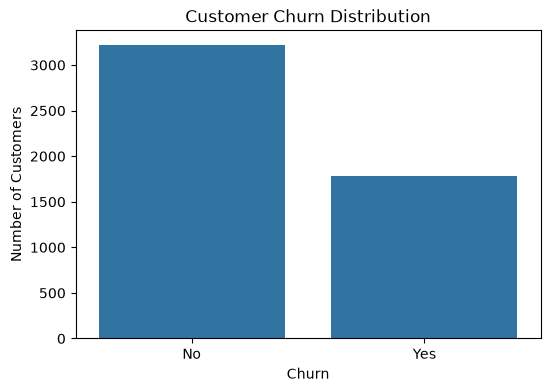

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [36]:
churn_rate = df["Churn"].value_counts(normalize=True) * 100

print(churn_rate)

Churn
No     64.36
Yes    35.64
Name: proportion, dtype: float64


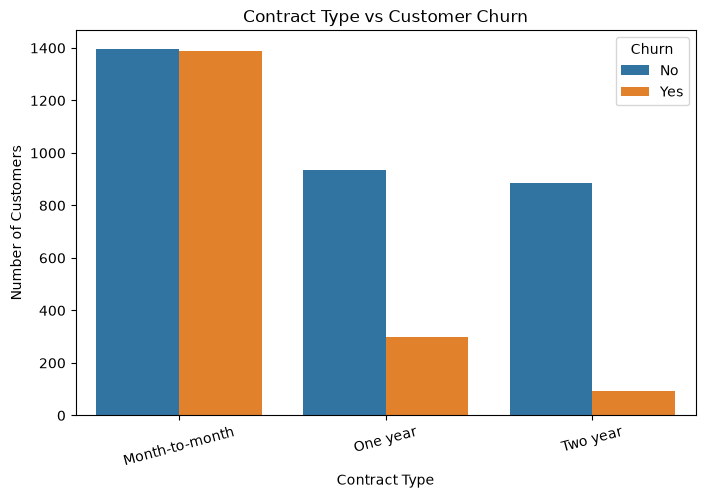

In [37]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)

plt.show()

In [38]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  50.125583  49.874417
One year        75.831306  24.168694
Two year        90.408163   9.591837


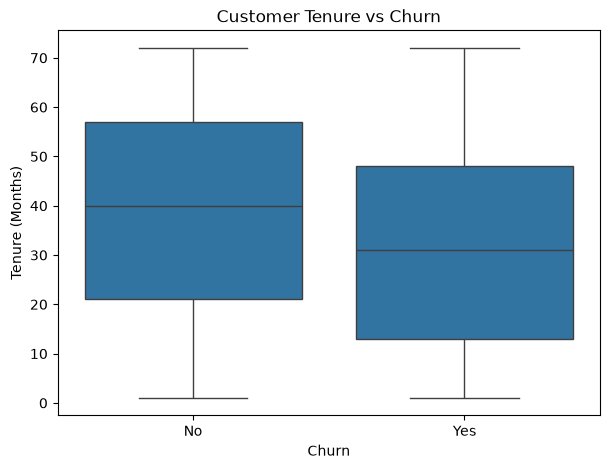

In [39]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [40]:
print(
    df.groupby("Churn")["tenure"].mean()
)

Churn
No     38.866377
Yes    31.725028
Name: tenure, dtype: float64


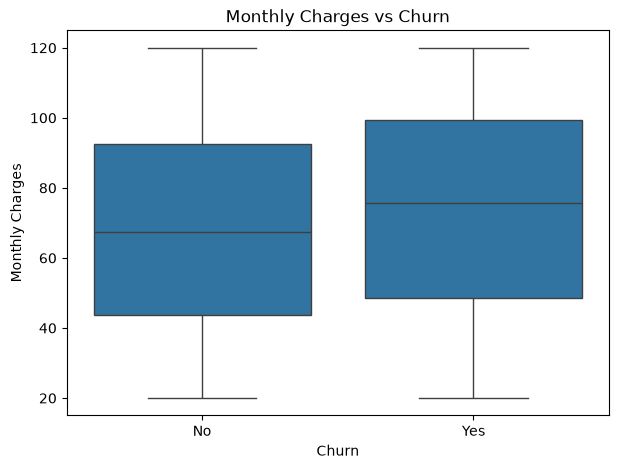

In [41]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [42]:
print(
    df.groupby("Churn")["MonthlyCharges"].mean()
)

Churn
No     68.125255
Yes    73.503053
Name: MonthlyCharges, dtype: float64


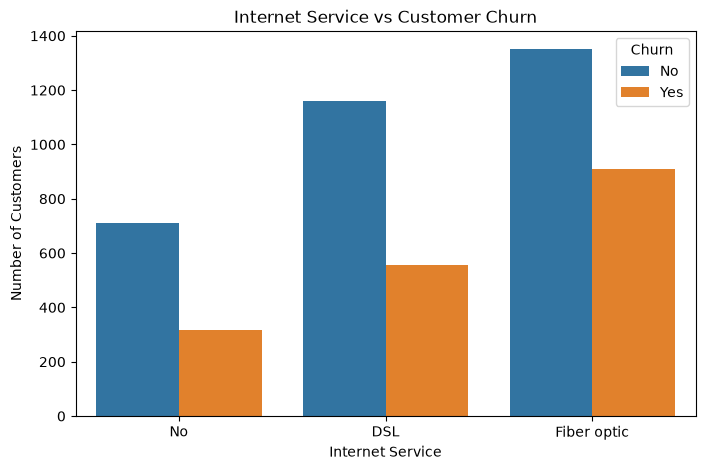

In [43]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Internet Service vs Customer Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [44]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn)

Churn                   No        Yes
InternetService                      
DSL              67.619603  32.380397
Fiber optic      59.708094  40.291906
No               69.170732  30.829268


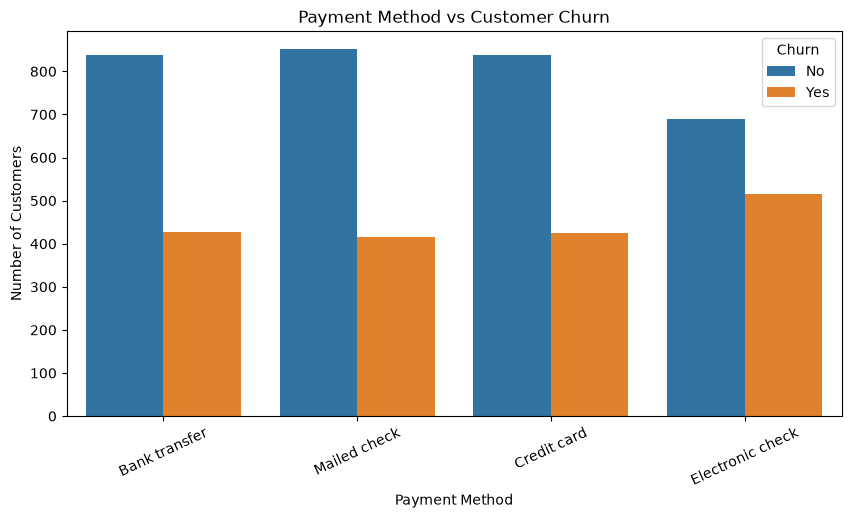

In [45]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Payment Method vs Customer Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=25)

plt.show()

In [46]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn)

Churn                    No        Yes
PaymentMethod                         
Bank transfer     66.271722  33.728278
Credit card       66.402536  33.597464
Electronic check  57.213930  42.786070
Mailed check      67.219589  32.780411


In [47]:
df["SeniorCitizenLabel"] = df["SeniorCitizen"].map({
    0: "Non-Senior",
    1: "Senior"
})

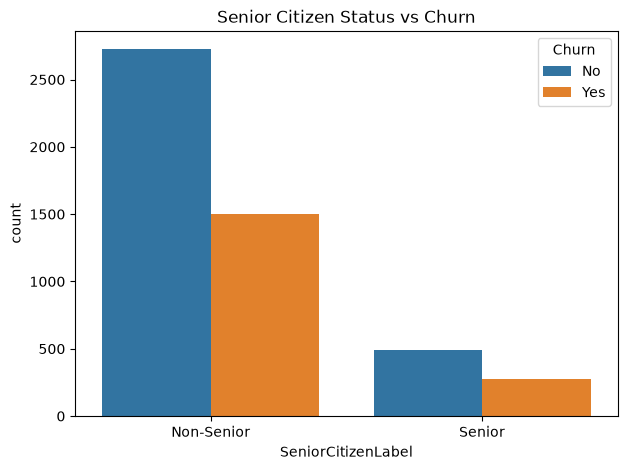

In [48]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="SeniorCitizenLabel",
    hue="Churn"
)

plt.title("Senior Citizen Status vs Churn")

plt.show()

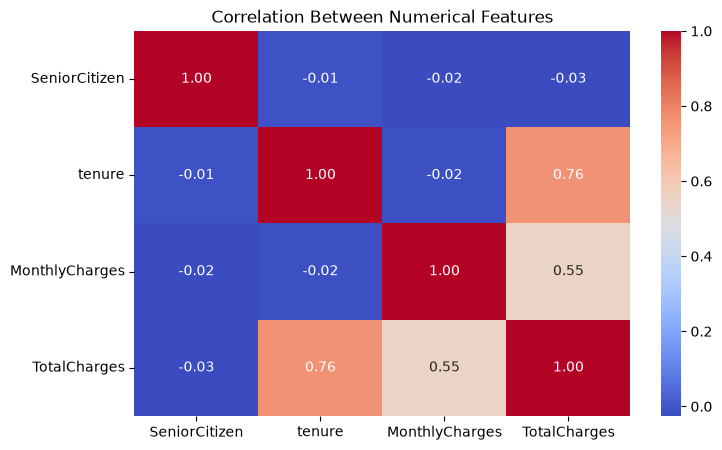

In [49]:
numeric_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

plt.figure(figsize=(8, 5))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")

plt.show()

## EDA Findings

1. The overall customer churn rate is approximately 35.64%.

2. Contract type shows differences in churn behavior across customer groups.

3. Customer tenure shows differences between churned and retained customers.

4. Monthly charges vary between churned and retained customers.

5. Internet service type shows different churn patterns.

6. Payment methods show differences in customer churn.

7. Numerical features show different levels of correlation with each other.

In [2]:
# Separate features and target

X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

NameError: name 'df' is not defined

In [ ]:
y = y.map({
    "No": 0,
    "Yes": 1
})

print(y.value_counts())

Churn
0    3218
1    1782
Name: count, dtype: int64


In [ ]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

print("Numerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'InternetService', 'Contract', 'PaymentMethod', 'SeniorCitizenLabel']


In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 12)
Testing data: (1000, 12)


In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (4000, 24)
Processed testing shape: (1000, 24)


In [ ]:
# Remove redundant SeniorCitizenLabel column

X = X.drop("SeniorCitizenLabel", axis=1)

# Re-identify columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

print("Numerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'InternetService', 'Contract', 'PaymentMethod']


In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (4000, 11)
Testing: (1000, 11)


In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training:", X_train_processed.shape)
print("Processed testing:", X_test_processed.shape)

Processed training: (4000, 22)
Processed testing: (1000, 22)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Predict churn class
y_pred_logistic = logistic_model.predict(X_test_processed)

# Predict churn probability
y_prob_logistic = logistic_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(y_pred_logistic[:10])

print("\nFirst 10 churn probabilities:")
print(y_prob_logistic[:10])

First 10 predictions:
[0 1 0 1 0 0 0 0 0 0]

First 10 churn probabilities:
[0.13039333 0.58393644 0.13081371 0.58847619 0.42438559 0.18116609
 0.11211588 0.25084603 0.1707883  0.04326866]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=10
)

# Train the model
random_forest_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
# Predict churn class
y_pred_rf = random_forest_model.predict(X_test_processed)

# Predict churn probability
y_prob_rf = random_forest_model.predict_proba(X_test_processed)[:, 1]

print("First 10 Random Forest predictions:")
print(y_pred_rf[:10])

print("\nFirst 10 Random Forest churn probabilities:")
print(y_prob_rf[:10])

First 10 Random Forest predictions:
[0 1 0 1 0 0 0 0 0 0]

First 10 Random Forest churn probabilities:
[0.14860029 0.65079193 0.29961889 0.72514448 0.35774662 0.25551313
 0.11025475 0.32180582 0.09934337 0.09187068]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [3]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Metrics imported successfully!")

Metrics imported successfully!


In [5]:
# ============================================================
# CUSTOMER CHURN PREDICTION
# STAGE 5 + STAGE 6
# COMPLETE RECOVERY CODE
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. LOAD CLEAN DATA
# ============================================================

df = pd.read_csv("../data/customer_churn_clean.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# ============================================================
# 2. REMOVE REDUNDANT COLUMN
# ============================================================

if "SeniorCitizenLabel" in df.columns:
    df = df.drop("SeniorCitizenLabel", axis=1)

# ============================================================
# 3. SEPARATE FEATURES AND TARGET
# ============================================================

X = df.drop("Churn", axis=1)

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("\nTarget distribution:")
print(y.value_counts())

# ============================================================
# 4. IDENTIFY FEATURES
# ============================================================

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("\nNumerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

# ============================================================
# 5. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# ============================================================
# 6. PREPROCESSING
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nProcessed training shape:",
      X_train_processed.shape)

print("Processed testing shape:",
      X_test_processed.shape)

# ============================================================
# 7. LOGISTIC REGRESSION
# ============================================================

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

y_pred_logistic = logistic_model.predict(
    X_test_processed
)

y_prob_logistic = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

print("\nLogistic Regression trained successfully!")

# ============================================================
# 8. RANDOM FOREST
# ============================================================

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

random_forest_model.fit(
    X_train_processed,
    y_train
)

y_pred_rf = random_forest_model.predict(
    X_test_processed
)

y_prob_rf = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

print("Random Forest trained successfully!")

# ============================================================
# 9. LOGISTIC REGRESSION EVALUATION
# ============================================================

print("\n")
print("=" * 60)
print("LOGISTIC REGRESSION RESULTS")
print("=" * 60)

log_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

log_precision = precision_score(
    y_test,
    y_pred_logistic
)

log_recall = recall_score(
    y_test,
    y_pred_logistic
)

log_f1 = f1_score(
    y_test,
    y_pred_logistic
)

log_roc_auc = roc_auc_score(
    y_test,
    y_prob_logistic
)

print("Accuracy :", round(log_accuracy, 4))
print("Precision:", round(log_precision, 4))
print("Recall   :", round(log_recall, 4))
print("F1-Score :", round(log_f1, 4))
print("ROC-AUC  :", round(log_roc_auc, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_logistic
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_logistic
))

# ============================================================
# 10. RANDOM FOREST EVALUATION
# ============================================================

print("\n")
print("=" * 60)
print("RANDOM FOREST RESULTS")
print("=" * 60)

rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_precision = precision_score(
    y_test,
    y_pred_rf
)

rf_recall = recall_score(
    y_test,
    y_pred_rf
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf
)

rf_roc_auc = roc_auc_score(
    y_test,
    y_prob_rf
)

print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1-Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_roc_auc, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_rf
))

# ============================================================
# 11. MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        log_accuracy,
        rf_accuracy
    ],
    "Precision": [
        log_precision,
        rf_precision
    ],
    "Recall": [
        log_recall,
        rf_recall
    ],
    "F1-Score": [
        log_f1,
        rf_f1
    ],
    "ROC-AUC": [
        log_roc_auc,
        rf_roc_auc
    ]
})

print("\n")
print("=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(comparison.round(4))

Dataset loaded successfully!
Dataset shape: (5000, 12)

Target distribution:
Churn
0    3218
1    1782
Name: count, dtype: int64

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'InternetService', 'Contract', 'PaymentMethod']


C:\Users\Dell\AppData\Local\Temp\ipykernel_13128\551093161.py:65: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(



Training shape: (4000, 11)
Testing shape: (1000, 11)

Processed training shape: (4000, 22)
Processed testing shape: (1000, 22)

Logistic Regression trained successfully!
Random Forest trained successfully!


LOGISTIC REGRESSION RESULTS
Accuracy : 0.687
Precision: 0.5734
Recall   : 0.4719
F1-Score : 0.5177
ROC-AUC  : 0.7457

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.81      0.77       644
           1       0.57      0.47      0.52       356

    accuracy                           0.69      1000
   macro avg       0.65      0.64      0.64      1000
weighted avg       0.68      0.69      0.68      1000

Confusion Matrix:
[[519 125]
 [188 168]]


RANDOM FOREST RESULTS
Accuracy : 0.667
Precision: 0.5434
Recall   : 0.4045
F1-Score : 0.4638
ROC-AUC  : 0.7286

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.81      0.76       644
           1       0.54      0.40   

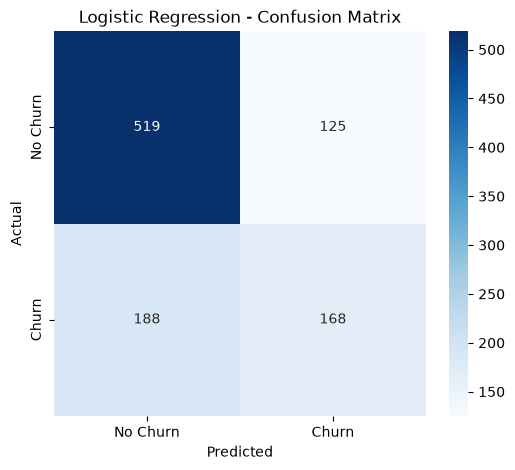

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

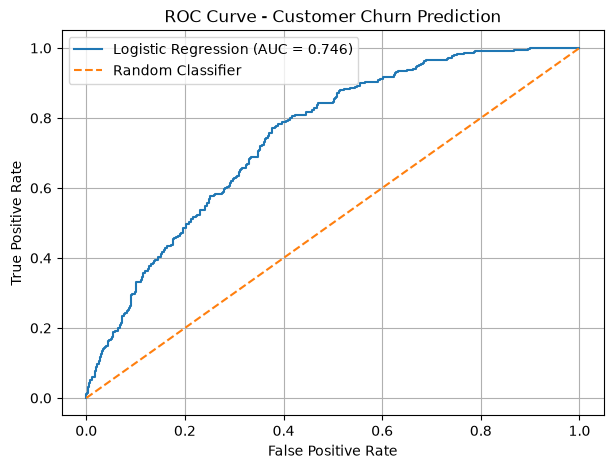

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_logistic
)

# Calculate ROC-AUC
roc_auc = roc_auc_score(
    y_test,
    y_prob_logistic
)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid()

plt.show()

In [8]:
import joblib
import os

# Create models directory
os.makedirs("../models", exist_ok=True)

# Save Logistic Regression model
joblib.dump(
    logistic_model,
    "../models/churn_model.pkl"
)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    "../models/preprocessor.pkl"
)

print("Model saved successfully!")
print("Preprocessor saved successfully!")

Model saved successfully!
Preprocessor saved successfully!
